In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [4]:
df = pd.read_csv("data/openfoodfacts_nn_ready_main.csv")
print(df.shape)
df.head()

(4429, 8)


,record_id,code,product_name,ingredients_text,ingredients_text_clean,target_nova_group,target_label,split
0,1,6111246721261,Fromage Blanc Nature,"Lait de Vache pasteurisé, Crème fraiche pasteu...","lait de vache pasteurisé, crème fraiche pasteu...",3,processed_foods,test
1,2,6111242100992,Perly,"milk cream, cream, sugar, banana, bacteria","milk cream, cream, sugar, banana, bacteria",3,processed_foods,train
2,3,6111035000058,Eau minérale naturelle,100% mineral water,100% mineral water,1,unprocessed_or_minimally_processed,train
3,4,6111035002175,Sidi Ali,"Sodium, Calcium, Magnésium, Potassium, Bicarbo...","sodium, calcium, magnésium, potassium, bicarbo...",1,unprocessed_or_minimally_processed,test
4,5,6111266962187,Lait,Lait frais pasteurisé demi-écrémé à 15g/l de m...,lait frais pasteurisé demi-écrémé à 15g/l de m...,3,processed_foods,test


In [5]:
print(df.columns.tolist())
print()
print(df["target_nova_group"].value_counts())
print()
print(df["split"].value_counts())

['record_id', 'code', 'product_name', 'ingredients_text', 'ingredients_text_clean', 'target_nova_group', 'target_label', 'split']

target_nova_group
4    2745
3    1108
1     453
2     123
Name: count, dtype: int64

split
train         3100
test           665
validation     664
Name: count, dtype: int64


In [6]:
print("Shape:", df.shape)
print()
print(df["target_nova_group"].value_counts())
print()
print(df["split"].value_counts())

Shape: (4429, 8)

target_nova_group
4    2745
3    1108
1     453
2     123
Name: count, dtype: int64

split
train         3100
test           665
validation     664
Name: count, dtype: int64


In [7]:
df = df.dropna(subset=["ingredients_text_clean", "target_nova_group", "split"]).copy()
df["ingredients_text_clean"] = df["ingredients_text_clean"].astype(str)

print(df.shape)

(4429, 8)


In [8]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

print("TRAIN:", train_df.shape)
print("VALIDATION:", val_df.shape)
print("TEST:", test_df.shape)

TRAIN: (3100, 8)
VALIDATION: (664, 8)
TEST: (665, 8)


In [9]:
X_train = train_df["ingredients_text_clean"].values
X_val = val_df["ingredients_text_clean"].values
X_test = test_df["ingredients_text_clean"].values

y_train = train_df["target_nova_group"].values
y_val = val_df["target_nova_group"].values
y_test = test_df["target_nova_group"].values

In [10]:
label_encoder = LabelEncoder()

y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

print("Klasy:", label_encoder.classes_)
print("Liczba klas:", len(label_encoder.classes_))

Klasy: [1 2 3 4]
Liczba klas: 4


In [11]:
max_tokens = 20000
sequence_length = 80

vectorize_layer = layers.TextVectorization(
    max_tokens=max_tokens,
    output_mode="int",
    output_sequence_length=sequence_length
)

vectorize_layer.adapt(X_train)

vocab = vectorize_layer.get_vocabulary()
print("Rozmiar słownika:", len(vocab))
print(vocab[:20])

Rozmiar słownika: 7123
['', '[UNK]', np.str_('de'), np.str_('d'), np.str_('sel'), np.str_('lait'), np.str_('blé'), np.str_('farine'), np.str_('sucre'), np.str_('huile'), np.str_('poudre'), np.str_('en'), np.str_('eau'), np.str_('cacao'), np.str_('5'), np.str_('et'), np.str_('à'), np.str_('soja'), np.str_('arôme'), np.str_('1')]


In [12]:
num_classes = len(label_encoder.classes_)

model = keras.Sequential([
    keras.Input(shape=(1,), dtype=tf.string),
    vectorize_layer,
    layers.Embedding(input_dim=max_tokens, output_dim=64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 80)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 80, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,354,564 (5.17 MB)

 Trainable params: 1,354,564 (5.17 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "best_nova_model.keras",
    monitor="val_loss",
    save_best_only=True
)

In [14]:
history = model.fit(
    X_train,
    y_train_enc,
    validation_data=(X_val, y_val_enc),
    epochs=12,
    batch_size=32,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/12
97/97 ━━━━━━━━━━━━━━━━━━━━ 20s 139ms/step - accuracy: 0.6371 - loss: 0.8585 - val_accuracy: 0.7364 - val_loss: 0.6289
Epoch 2/12
97/97 ━━━━━━━━━━━━━━━━━━━━ 12s 126ms/step - accuracy: 0.8287 - loss: 0.4393 - val_accuracy: 0.8630 - val_loss: 0.4241
Epoch 3/12
97/97 ━━━━━━━━━━━━━━━━━━━━ 20s 125ms/step - accuracy: 0.9252 - loss: 0.2552 - val_accuracy: 0.8705 - val_loss: 0.3969
Epoch 4/12
97/97 ━━━━━━━━━━━━━━━━━━━━ 20s 125ms/step - accuracy: 0.9397 - loss: 0.1819 - val_accuracy: 0.8599 - val_loss: 0.3824
Epoch 5/12
97/97 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.9506 - loss: 0.1360 - val_accuracy: 0.8705 - val_loss: 0.3962
Epoch 6/12
97/97 ━━━━━━━━━━━━━━━━━━━━ 12s 122ms/step - accuracy: 0.9565 - loss: 0.1244 - val_accuracy: 0.8750 - val_loss: 0.3817
Epoch 7/12
97/97 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accuracy: 0.9700 - loss: 0.0925 - val_accuracy: 0.8855 - val_loss: 0.4145
Epoch 8/12
97/97 ━━━━━━━━━━━━━━━━━━━━ 12s 121ms/step - accuracy: 0.9839 - loss: 0.0581 - val_accu

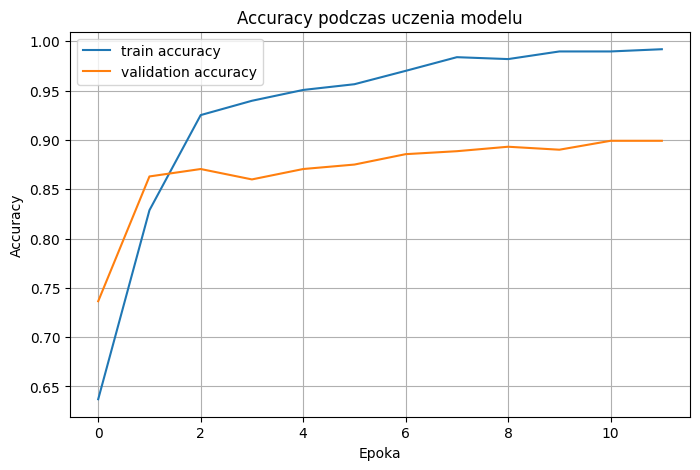

In [15]:
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.title("Accuracy podczas uczenia modelu")
plt.xlabel("Epoka")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

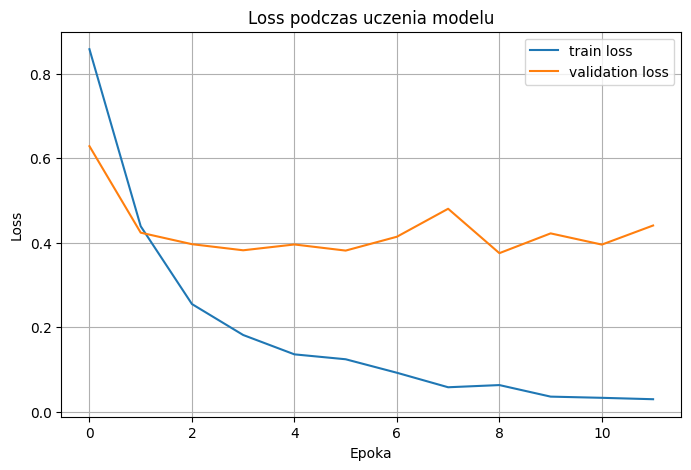

In [16]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.title("Loss podczas uczenia modelu")
plt.xlabel("Epoka")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
test_loss, test_acc = model.evaluate(X_test, y_test_enc, verbose=0)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_acc, 4))

Test loss: 0.4032
Test accuracy: 0.8887


In [18]:
y_pred_probs = model.predict(X_test)
y_pred_enc = np.argmax(y_pred_probs, axis=1)

y_pred = label_encoder.inverse_transform(y_pred_enc)

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step


In [19]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.84      0.68      0.75        68
           2       0.61      0.58      0.59        19
           3       0.81      0.83      0.82       166
           4       0.94      0.96      0.95       412

    accuracy                           0.89       665
   macro avg       0.80      0.76      0.78       665
weighted avg       0.89      0.89      0.89       665



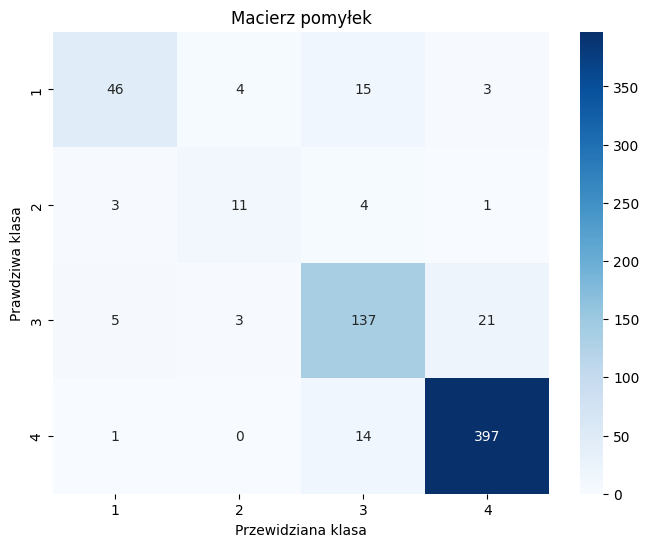

In [20]:
cm = confusion_matrix(y_test, y_pred, labels=label_encoder.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Macierz pomyłek")
plt.xlabel("Przewidziana klasa")
plt.ylabel("Prawdziwa klasa")
plt.show()

In [21]:
results_df = pd.DataFrame({
    "ingredients_text_clean": X_test,
    "true_label": y_test,
    "pred_label": y_pred
})

errors_df = results_df[results_df["true_label"] != results_df["pred_label"]].copy()
print("Liczba błędów:", errors_df.shape[0])
errors_df.head(20)

Liczba błędów: 74


,ingredients_text_clean,true_label,pred_label
2,lait frais pasteurisé demi-écrémé à 15g/l de m...,3,1
3,aqua,1,2
25,lait entier pasteurisé,1,3
37,"lait de vache pasteurisé, crème pasteurisée, f...",1,3
56,"pasteurized fresh milk 53% (origin: france), c...",4,3
62,"cacao desgrasado en polvo, correctores de acid...",1,4
65,"lait entier, poudre de lait ecrémé, ferments l...",3,1
78,natürliches mineralwasser mit kohlensäure,1,4
94,"lait de vache pasteurisé, crème fraiche pasteu...",1,3
113,"wheat flour, sugar, vegetable oils (palm oil, ...",3,4


In [22]:
model.save("nova_text_model_final.keras")
print("Model zapisany.")

Model zapisany.


In [23]:
import numpy as np
import pandas as pd

sample_products = [
    "water",
    "milk, lactic ferments",
    "tomatoes, olive oil, salt",
    "sugar, palm oil, hazelnuts, cocoa, skimmed milk powder, emulsifier soy lecithin, vanillin",
    "wheat flour, sugar, palm oil, glucose syrup, emulsifier, flavouring, raising agents",
    "oats, raisins, almonds",
    "carbonated water, colour e150d, phosphoric acid, aspartame, acesulfame-k, flavourings",
    "potatoes, sunflower oil, salt"
]

sample_products_np = np.array(sample_products, dtype=object)

pred_probs = model.predict(sample_products_np, verbose=0)
pred_classes = np.argmax(pred_probs, axis=1)
pred_labels = label_encoder.inverse_transform(pred_classes)

results = pd.DataFrame({
    "ingredients_text": sample_products,
    "predicted_class_num": pred_labels
})

results["predicted_class"] = results["predicted_class_num"].apply(lambda x: f"NOVA_{x}")

for i in range(pred_probs.shape[1]):
    results[f"prob_NOVA_{i+1}"] = pred_probs[:, i]

results

,ingredients_text,predicted_class_num,predicted_class,prob_NOVA_1,prob_NOVA_2,prob_NOVA_3,prob_NOVA_4
0,water,1,NOVA_1,9.495030e-01,4.224603e-02,0.007082,0.001168
1,"milk, lactic ferments",1,NOVA_1,7.986472e-01,1.549221e-01,0.043159,0.003271
2,"tomatoes, olive oil, salt",3,NOVA_3,3.771984e-04,1.146308e-02,0.985614,0.002546
3,"sugar, palm oil, hazelnuts, cocoa, skimmed mil...",4,NOVA_4,2.341470e-06,9.271329e-05,0.000282,0.999623
4,"wheat flour, sugar, palm oil, glucose syrup, e...",4,NOVA_4,1.640044e-08,9.626335e-07,0.000021,0.999978
5,"oats, raisins, almonds",3,NOVA_3,1.008290e-01,5.716682e-02,0.820431,0.021573
6,"carbonated water, colour e150d, phosphoric aci...",4,NOVA_4,1.061788e-06,3.486746e-05,0.000138,0.999826
7,"potatoes, sunflower oil, salt",3,NOVA_3,5.119498e-05,6.730708e-04,0.962375,0.036900


In [24]:
import numpy as np
import pandas as pd

sample_products = [
    "water",
    "milk, lactic ferments",
    "tomatoes, olive oil, salt",
    "sugar, palm oil, hazelnuts, cocoa, skimmed milk powder, emulsifier soy lecithin, vanillin",
    "wheat flour, sugar, palm oil, glucose syrup, emulsifier, flavouring, raising agents",
    "oats, raisins, almonds",
    "carbonated water, colour e150d, phosphoric acid, aspartame, acesulfame-k, flavourings",
    "potatoes, sunflower oil, salt",
    "sugar",
    "salt",
    "olive oil",
    "sunflower oil",
    "butter",
    "honey",
    "maple syrup",
    "vinegar",
    "corn starch",
    "potato starch",
    "glucose syrup",
    "rapeseed oil",
    "coconut oil",
    "ghee",
    "apple cider vinegar",
    "table sugar",
    "sea salt",
    "wheat flour, water, yeast, salt",
    "tomato puree, basil, salt",
    "peanuts 100%",
    "cocoa mass, cocoa butter, sugar",
    "water, sugar, lemon juice concentrate"
]

sample_products_np = np.array(sample_products, dtype=object)

pred_probs = model.predict(sample_products_np, verbose=0)
pred_classes = np.argmax(pred_probs, axis=1)
pred_labels = label_encoder.inverse_transform(pred_classes)

results = pd.DataFrame({
    "ingredients_text": sample_products,
    "predicted_class_num": pred_labels
})

results["predicted_class"] = results["predicted_class_num"].apply(lambda x: f"NOVA_{x}")

for i in range(pred_probs.shape[1]):
    results[f"prob_NOVA_{i+1}"] = pred_probs[:, i]

results

,ingredients_text,predicted_class_num,predicted_class,prob_NOVA_1,prob_NOVA_2,prob_NOVA_3,prob_NOVA_4
0,water,1,NOVA_1,9.495030e-01,4.224603e-02,0.007082,0.001168
1,"milk, lactic ferments",1,NOVA_1,7.986472e-01,1.549221e-01,0.043159,0.003271
2,"tomatoes, olive oil, salt",3,NOVA_3,3.771984e-04,1.146308e-02,0.985614,0.002546
3,"sugar, palm oil, hazelnuts, cocoa, skimmed mil...",4,NOVA_4,2.341470e-06,9.271329e-05,0.000282,0.999623
4,"wheat flour, sugar, palm oil, glucose syrup, e...",4,NOVA_4,1.640044e-08,9.626335e-07,0.000021,0.999978
5,"oats, raisins, almonds",3,NOVA_3,1.008290e-01,5.716682e-02,0.820431,0.021573
6,"carbonated water, colour e150d, phosphoric aci...",4,NOVA_4,1.061788e-06,3.486746e-05,0.000138,0.999826
7,"potatoes, sunflower oil, salt",3,NOVA_3,5.119498e-05,6.730708e-04,0.962375,0.036900
8,sugar,4,NOVA_4,4.046575e-02,3.046484e-01,0.286037,0.368848
9,salt,3,NOVA_3,3.153947e-03,2.879604e-02,0.929188,0.038862
